In [3]:
%pip install matplotlib
import rasterio
import numpy as np
import matplotlib.pyplot as plt


  Using cached contourpy-1.3.3-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.4.9-cp312-cp312-macosx_11_0_arm64.whl.metadata (6.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 22.9 MB/s eta 0:00:00a 0:00:01
Using cached contourpy-1.3.3-cp312-cp312-macosx_11_0_arm64.whl (273 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 15.7 MB/s eta 0:00:00
Using cached kiwisolver-1.4.9-cp312-cp312-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 22.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [4]:
# Charger l'image GeoTIFF
src = rasterio.open('/Users/karimkebe/Desktop/EAKK_JUPI/EAKK/Dakar_MNE_5m.tif')

In [5]:
# Lire les 3 bandes (Rouge, Vert, Bleu)
# Vérifier d'abord le nombre de bandes dans le dataset ouvert (src)
if src.count >= 3:
	red = src.read(1).astype(float)
	green = src.read(2).astype(float)
	blue = src.read(3).astype(float)
else:
	# Si le fichier ouvert ne contient qu'une seule bande, essayer d'ouvrir
	# un fichier "true color" si vous en avez un, sinon dupliquer la bande
	# existante pour obtenir une image RGB.
	rgb_path = r"/Users/karimkebe/Desktop/EAKK_JUPI/EAKK/DAKAR VRAI COUEUR2.tif"  # ajuster si nécessaire
	try:
		with rasterio.open(rgb_path) as rgb_src:
			if rgb_src.count >= 3:
				red = rgb_src.read(1).astype(float)
				green = rgb_src.read(2).astype(float)
				blue = rgb_src.read(3).astype(float)
			else:
				# fallback si le fichier RGB n'a pas 3 bandes
				single = src.read(1).astype(float)
				red = single.copy()
				green = single.copy()
				blue = single.copy()
				print("Le fichier RGB de remplacement n'a pas 3 bandes — utilisation de la bande unique du MNE pour RGB.")
	except Exception:
		# fallback final : dupliquer la bande unique du src
		single = src.read(1).astype(float)
		red = single.copy()
		green = single.copy()
		blue = single.copy()
		print("Impossible d'ouvrir le fichier RGB de remplacement — utilisation de la bande unique du MNE pour RGB.")


In [6]:
# Normalisation (0-1)
red /= red.max()
green /= green.max()
blue /= blue.max()


In [7]:
# Empiler les 3 bandes pour former une image RGB
rgb = np.dstack((red, green, blue))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9651213379973765e+304..1.0].


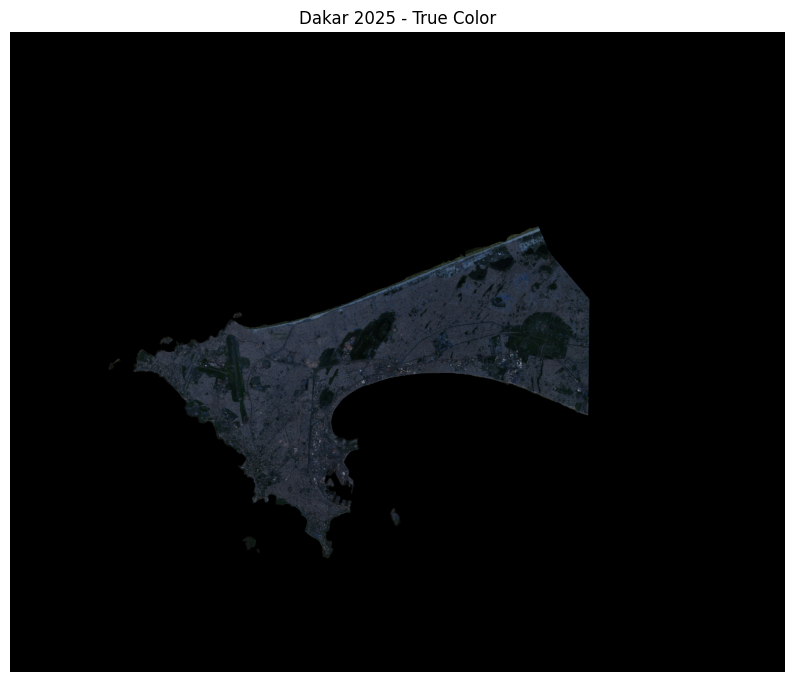

In [8]:
# Affichage
plt.figure(figsize=(10,10))
plt.imshow(rgb)
plt.title("Dakar 2025 - True Color")
plt.axis("off")
plt.show()


In [9]:

# Charger les packages nécessaires
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import rasterio

In [10]:
# 1. Charger le MNT
# -----------------------------
mnt_path = '/Users/karimkebe/Desktop/EAKK_JUPI/EAKK/Dakar_MNE_5m.tif'

with rasterio.open(mnt_path) as src:
    dem = src.read(1).astype(float)     # lecture 1ère bande
    dem[dem == src.nodata] = np.nan     # remplacer nodata par NaN
    transform = src.transform
    crs = src.crs

print("Dimensions :", dem.shape)
print("CRS :", crs)


Dimensions : (3697, 5088)
CRS : EPSG:32628


In [12]:
# 1. Charger le MNT
# -----------------------------
# mnt_path is already defined from previous cell
# dem, transform, and crs are already loaded from previous cell

print("Dimensions :", dem.shape)
print("CRS :", crs)


Dimensions : (3697, 5088)
CRS : EPSG:32628


In [13]:
# 2. Détecter zones inondables et inondées
# -----------------------------
seuil_inondable = 5 # m
seuil_inondee = 2    # m

zones_inondables = dem <= seuil_inondable
zones_inondees = dem <= seuil_inondee

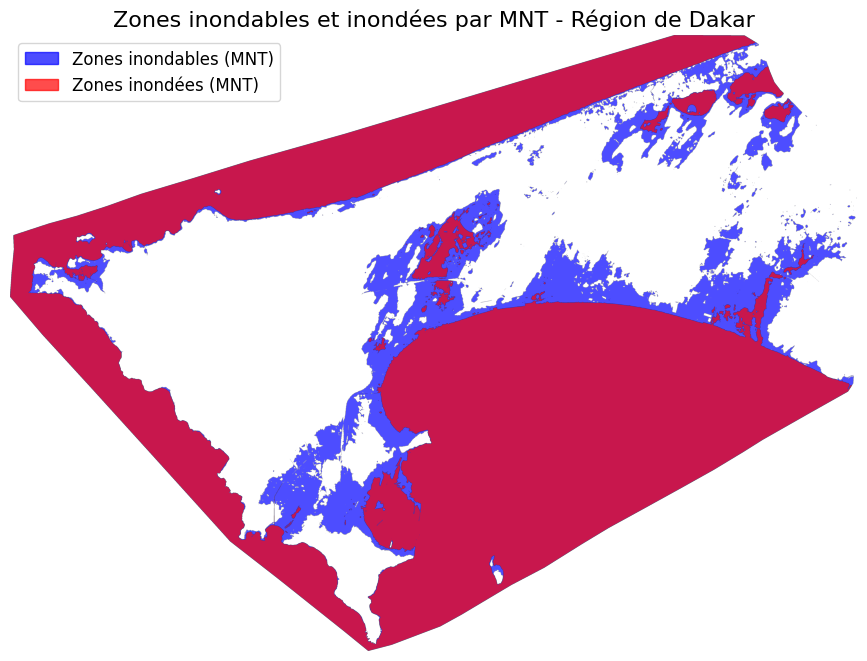

In [14]:
plt.figure(figsize=(12, 8))

# Zones inondables (bleu)
plt.imshow(np.where(zones_inondables, 1, np.nan), cmap=ListedColormap(['blue']), alpha=0.7)

# Zones inondées (rouge)
plt.imshow(np.where(zones_inondees, 1, np.nan), cmap=ListedColormap(['red']), alpha=0.7)

# Légende à gauche
blue_patch = mpatches.Patch(color='blue', alpha=0.7, label='Zones inondables (MNT)')
red_patch = mpatches.Patch(color='red', alpha=0.7, label='Zones inondées (MNT)')
plt.legend(handles=[blue_patch, red_patch], fontsize=12, loc='upper left')

plt.title("Zones inondables et inondées par MNT - Région de Dakar", fontsize=16)
plt.axis('off')  # enlever axes
plt.show()


In [15]:
#charger les packages neccesaire
import rasterio
import numpy as np
import matplotlib.pyplot as plt


In [16]:
# Charger bandes Green (B3) et NIR (B8)
green = rasterio.open('/Users/karimkebe/Desktop/EAKK_JUPI/EAKK/b32.tif').read(1).astype(float)
nir = rasterio.open('/Users/karimkebe/Desktop/EAKK_JUPI/EAKK/b82.tif').read(1).astype(float)


In [17]:
# Eviter la division par zéro
ndwi = (green - nir) / (green + nir + 1e-10)

/var/folders/03/z58spvlx09l_nf1kr_03yt7w0000gn/T/ipykernel_40161/2015286516.py:2: RuntimeWarning: overflow encountered in add
  ndwi = (green - nir) / (green + nir + 1e-10)


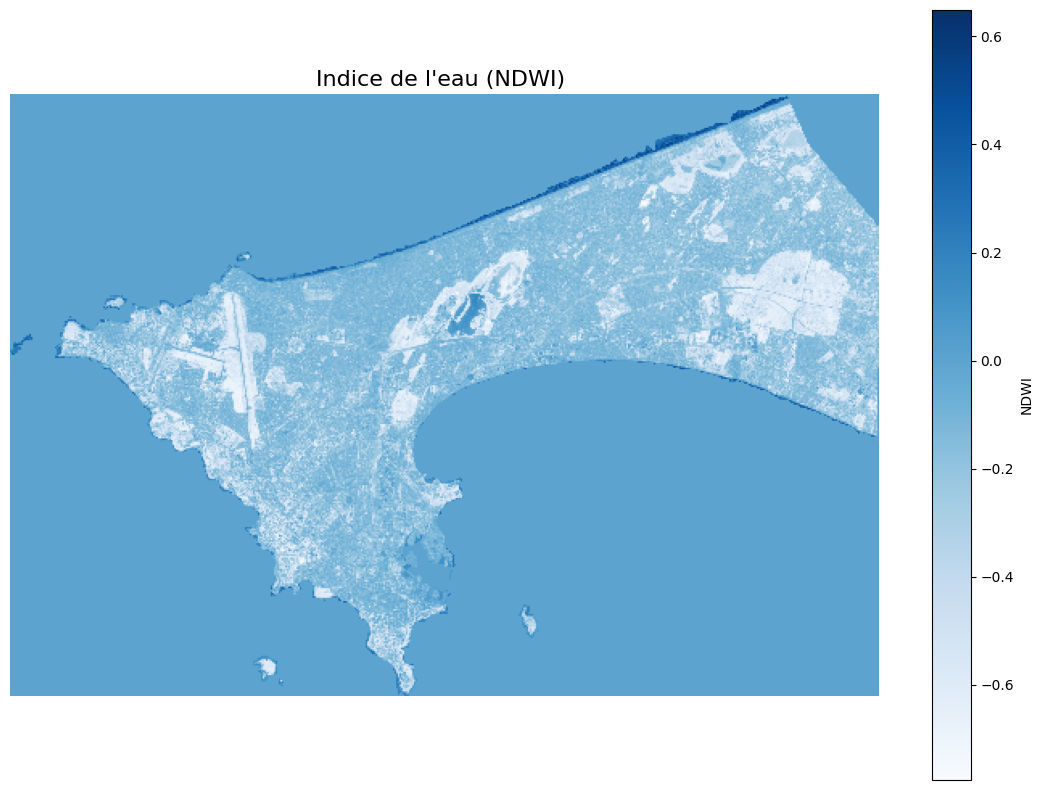

In [18]:


# Version réduite NDWI (1 pixel sur 5)
ndwi_small = ndwi[::5, ::5]  # prend 1 pixel sur 5

# Création de la figure avec fond blanc et taille augmentée
plt.figure(figsize=(14, 10), facecolor='white')  # Taille plus grande

# Affichage NDWI
plt.imshow(ndwi_small, cmap='Blues')
plt.colorbar(label='NDWI')

# Titre
plt.title("Indice de l'eau (NDWI) ", fontsize=16)

# Supprimer les axes
plt.axis('off')

# Afficher
plt.show()


In [19]:
# Packages
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches


In [20]:
# =========================
# 1. IMAGE EN VRAIES COULEURS
# =========================
with rasterio.open('/Users/karimkebe/Desktop/EAKK_JUPI/EAKK/DAKAR VRAI COUEUR2.tif') as src:
    red = src.read(1).astype(float)
    green = src.read(2).astype(float)
    blue = src.read(3).astype(float)


In [21]:
# Normalisation
red /= red.max()
green /= green.max()
blue /= blue.max()

rgb = np.dstack((red, green, blue))

In [23]:
# =========================
# 2. MNT + ZONES INONDABLES
# =========================
mnt_path = '/Users/karimkebe/Desktop/EAKK_JUPI/EAKK/Dakar_MNE_5m.tif'
with rasterio.open(mnt_path) as src:
    dem = src.read(1).astype(float)
    dem[dem == src.nodata] = np.nan


In [24]:
# Seuils (en m)
seuil_inondable = 5
seuil_inondee = 2

zones_inondables = dem <= seuil_inondable
zones_inondees = dem <= seuil_inondee


In [25]:
# 3. NDWI
# =========================
green_band = rasterio.open('/Users/karimkebe/Desktop/EAKK_JUPI/EAKK/b32.tif').read(1).astype(float)
nir_band = rasterio.open('/Users/karimkebe/Desktop/EAKK_JUPI/EAKK/b82.tif').read(1).astype(float)

ndwi = (green_band - nir_band) / (green_band + nir_band + 1e-10)
ndwi_small = ndwi[::5, ::5]  # réduction pour affichage rapide


/var/folders/03/z58spvlx09l_nf1kr_03yt7w0000gn/T/ipykernel_40161/1232016960.py:6: RuntimeWarning: overflow encountered in add
  ndwi = (green_band - nir_band) / (green_band + nir_band + 1e-10)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9651213379973765e+304..1.0].


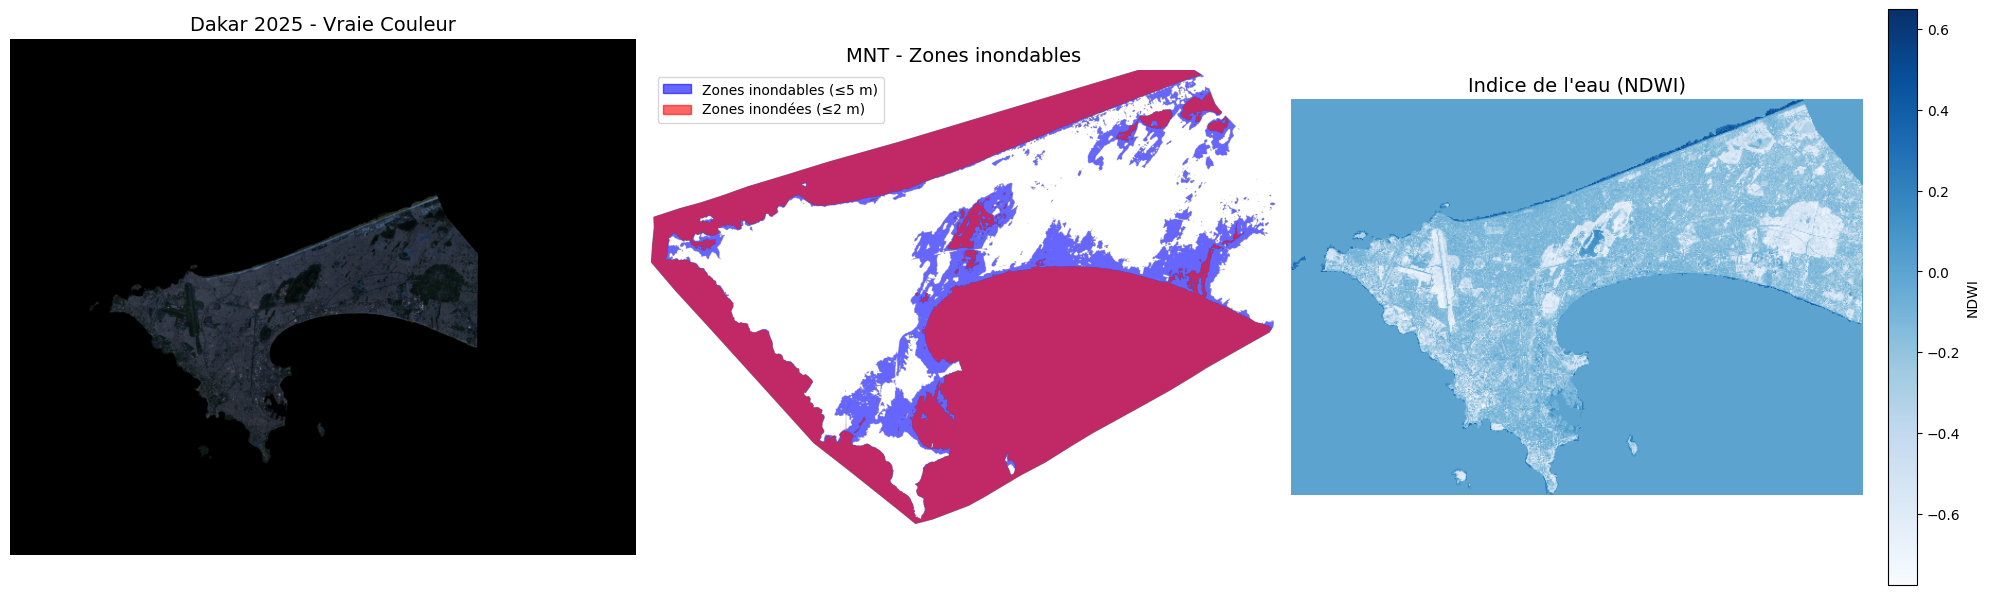

In [26]:
# FIGURE AVEC 3 CARTES
# =========================
fig, axes = plt.subplots(1, 3, figsize=(20, 8), facecolor="white")

# --- (1) Image RGB ---
axes[0].imshow(rgb)
axes[0].set_title("Dakar 2025 - Vraie Couleur", fontsize=14)
axes[0].axis("off")

# --- (2) Zones inondables ---
axes[1].imshow(np.where(zones_inondables, 1, np.nan), cmap=ListedColormap(['blue']), alpha=0.6)
axes[1].imshow(np.where(zones_inondees, 1, np.nan), cmap=ListedColormap(['red']), alpha=0.6)
blue_patch = mpatches.Patch(color='blue', alpha=0.6, label='Zones inondables (≤5 m)')
red_patch = mpatches.Patch(color='red', alpha=0.6, label='Zones inondées (≤2 m)')
axes[1].legend(handles=[blue_patch, red_patch], fontsize=10, loc='upper left')
axes[1].set_title("MNT - Zones inondables", fontsize=14)
axes[1].axis("off")

# --- (3) NDWI ---
im = axes[2].imshow(ndwi_small, cmap='Blues')
axes[2].set_title("Indice de l'eau (NDWI)", fontsize=14)
axes[2].axis("off")
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04, label="NDWI")

plt.tight_layout()
plt.show()
